# Carnet de démarrage — sujet 02 · Favorita

**Objectif du sujet** : prévoir les ventes d'un article, par magasin, sur 16 jours.

Ce carnet est un **châssis**, pas une solution. Il fait quatre choses et s'arrête :

1. il **trouve** vos fichiers, quelle que soit la plateforme ;
2. il **charge** la table efficacement — cache Parquet construit une fois, projection de colonnes ;
3. il **profile** les données : dimensions, types, cible, manquants ;
4. il **écrit** une soumission au bon format, avec une valeur de référence volontairement nulle.

**Ce qu'il ne fait pas** : choisir votre métrique, votre découpage de validation, votre modèle, ni vos
variables. Ces décisions sont le sujet, et c'est ce que la grille note.

12,2 M de lignes. `horizon.csv` est une grille dense, sans cible. Les ventes négatives sont des retours.

---

## Où mettre ce carnet

| Plateforme | Ce qu'il faut faire |
|---|---|
| **Le dossier du sujet** | **https://drive.google.com/drive/folders/1N1EJk5sY8cJ3PFtipJFbMFJIG2AqUYYl?usp=sharing** — téléchargez-le avant tout (le lien figure aussi dans l'énoncé) |
| **En local (VS Code, Jupyter)** | placez le carnet **dans le dossier téléchargé**, ou définissez `DONNEES_PROJET` vers ce dossier |
| **Google Colab** | déposez les fichiers dans `MyDrive/Sujet_02_Favorita/` — le carnet les trouvera ; ou téléversez-les dans `/content/` |
| **Kaggle** | créez un jeu de données avec vos fichiers, **Add Input** — `/kaggle/input` est exploré automatiquement |

**Rien n'est codé en dur** : le carnet cherche, et s'il ne trouve pas, il **dit précisément** ce qu'il a
cherché et où.


## Les fichiers de ce sujet

| Fichier | Rôle |
|---|---|
| `train.csv` | entraînement ou annexe |
| `horizon.csv` | à prédire — la cible est absente |
| `items.csv` | entraînement ou annexe |
| `stores.csv` | entraînement ou annexe |
| `holidays_events.csv` | entraînement ou annexe |
| `oil.csv` | entraînement ou annexe |
| `transactions.csv` | entraînement ou annexe |

**Format de sortie attendu** : `id,unit_sales`.
**Colonne d'identifiant** : `id`.
**Fichier à produire** : `soumission.csv`, à la racine de votre dépôt.


# Favorita — Sujet 02

**Séance :** 01  
**Nom :** ALIA Holmi

**Porteur :** P3  

**Étapes assignées :**  
1.6 : trous  
1.4 : cardinalité  
1.9 : cibles

## Sur les données lourdes — et pourquoi pas « raylib »

`raylib` est une bibliothèque **graphique** (fenêtres, dessin, jeux) : elle ne lit aucune table. Elle
n'a rien à faire ici. Les outils qui répondent au besoin sont :

| Outil | Rôle | Présent par défaut ? |
|---|---|---|
| **Parquet + pyarrow** | format colonne compressé, lecture sélective | **oui** avec pandas récent |
| **Polars** | moteur colonne, `scan_csv` paresseux | non — `pip install polars` |
| **DuckDB** | SQL directement sur CSV/Parquet, sans chargement | non — `pip install duckdb` |

Ce carnet utilise **Parquet** (garanti), et le remplace par Polars ou DuckDB si vous les installez. Le
principe ne change pas : **ne jamais charger ce dont on n'a pas besoin**, et **payer la conversion
CSV → Parquet une seule fois**.


In [1]:
# --- 1. Réglages --------------------------------------------------------------
from pathlib import Path
import os
import pandas as pd

# Où télécharger vos données — le dossier de votre sujet sur le Drive du cours.
LIEN_DRIVE = "https://drive.google.com/drive/folders/1N1EJk5sY8cJ3PFtipJFbMFJIG2AqUYYl?usp=sharing —"

# ECHANTILLON : nombre de lignes lues pour démarrer. None = tout lire.
ECHANTILLON = 200_000
DOSSIER_CACHE = Path.cwd() / "_cache_parquet"


In [2]:
from pathlib import Path
print("dossier courant :", Path.cwd())
print("contenu :", sorted(p.name for p in Path.cwd().iterdir())[:30])

dossier courant : /kaggle/working
contenu : []


In [3]:
# --- 2. Trouver les données
import os
from pathlib import Path

dossier = Path.cwd() / "Projet_app_auto"
print(dossier.exists(), sorted(p.name for p in dossier.iterdir())[:12] if dossier.exists() else "")
os.environ["DONNEES_PROJET"] = str(dossier)

False 


In [4]:
import os
from pathlib import Path

FICHIERS = ['train.csv', 'horizon.csv', 'items.csv', 'stores.csv',
            'holidays_events.csv', 'oil.csv', 'transactions.csv']

trouve = None
for racine, dossiers, fichiers in os.walk("/kaggle/input"):
    print(racine, "->", sorted(fichiers)[:8])
    if all(f in fichiers for f in FICHIERS):
        trouve = racine

if trouve:
    os.environ["DONNEES_PROJET"] = trouve
    print("\nDossier trouvé et enregistré :", trouve)
else:
    print("\nLes 7 fichiers ne sont pas ensemble dans un même dossier.")

/kaggle/input -> []
/kaggle/input/datasets -> []
/kaggle/input/datasets/holmialia -> []
/kaggle/input/datasets/holmialia/favorita-data -> ['holidays_events.csv', 'horizon.csv', 'items.csv', 'oil.csv', 'stores.csv', 'train.csv', 'transactions.csv']

Dossier trouvé et enregistré : /kaggle/input/datasets/holmialia/favorita-data


In [5]:
for nom in ["DOSSIER", "ECHANTILLON", "DOSSIER_CACHE", "FICHIERS_ATTENDUS", "table", "pd"]:
    print(nom, "->", "défini" if nom in globals() else "MANQUANT")

DOSSIER -> MANQUANT
ECHANTILLON -> défini
DOSSIER_CACHE -> défini
FICHIERS_ATTENDUS -> MANQUANT
table -> MANQUANT
pd -> défini


In [6]:
# --- 3. Chargement efficace (table lourde) ------------------------------------
# Le cache Parquet s'écrit à côté du carnet, jamais dans les données : sur Kaggle,
# /kaggle/input est en lecture seule.
import pyarrow as pa
import pyarrow.csv as pvc
import pyarrow.parquet as pq


def table(nom, colonnes=None, complet=False):
    """Ouvre un CSV en profitant d'un cache Parquet.

    nom      : nom du fichier dans le dossier de données
    colonnes : liste de colonnes à garder (None = toutes) — le levier principal
    """
    source = DOSSIER / nom
    if not source.is_file():
        raise FileNotFoundError(f"{nom} introuvable dans {DOSSIER}")

    # lecture d'un échantillon : pas de cache, on veut seulement voir
    if ECHANTILLON and not complet:
        lots, reste = [], ECHANTILLON
        for lot in pvc.open_csv(str(source), read_options=pvc.ReadOptions(block_size=1 << 25)):
            lots.append(lot)
            reste -= lot.num_rows
            if reste <= 0:
                break
        t = pa.Table.from_batches(lots)
        if colonnes:
            t = t.select([c for c in colonnes if c in t.column_names])
        return t.to_pandas()

    # cache Parquet, construit une fois
    cache = DOSSIER_CACHE / (Path(nom).stem + ".parquet")
    if not cache.is_file():
        DOSSIER_CACHE.mkdir(parents=True, exist_ok=True)
        print(f"construction du cache Parquet : {cache.name} (une seule fois)")
        ecrivain = None
        try:
            for lot in pvc.open_csv(str(source), read_options=pvc.ReadOptions(block_size=1 << 26)):
                if colonnes:
                    lot = lot.select([c for c in colonnes if c in lot.schema.names])
                if ecrivain is None:
                    ecrivain = pq.ParquetWriter(cache, lot.schema)
                ecrivain.write_batch(lot)
        finally:
            if ecrivain is not None:
                ecrivain.close()
    fichier = pq.ParquetFile(cache)
    return fichier.read(columns=colonnes).to_pandas()


def table_par_morceaux(nom, colonnes=None, morceaux=200_000):
    """Itère sur la table par paquets — pour les traitements qui ne tiennent pas en mémoire."""
    table(nom, colonnes=colonnes)          # garantit que le cache existe
    cache = DOSSIER_CACHE / (Path(nom).stem + ".parquet")
    for lot in pq.ParquetFile(cache).iter_batches(batch_size=morceaux):
        yield lot.to_pandas()

In [7]:
import os
from pathlib import Path
import pandas as pd

FICHIERS_ATTENDUS = ['train.csv', 'horizon.csv', 'items.csv', 'stores.csv',
                     'holidays_events.csv', 'oil.csv', 'transactions.csv']

DOSSIER = None
for racine, dossiers, fichiers in os.walk("/kaggle/input"):
    if all(f in fichiers for f in FICHIERS_ATTENDUS):
        DOSSIER = Path(racine)

if DOSSIER is None:
    for racine, dossiers, fichiers in os.walk("/kaggle/input"):
        print(racine, "->", sorted(fichiers)[:8])
    raise FileNotFoundError("Les 7 fichiers ne sont pas ensemble dans un même dossier (voir la liste ci-dessus).")

os.environ["DONNEES_PROJET"] = str(DOSSIER)
print("dossier de données :", DOSSIER)
print("fichiers vus :", sorted(p.name for p in DOSSIER.iterdir() if p.is_file()))

dossier de données : /kaggle/input/datasets/holmialia/favorita-data
fichiers vus : ['holidays_events.csv', 'horizon.csv', 'items.csv', 'oil.csv', 'stores.csv', 'train.csv', 'transactions.csv']


In [8]:
# --- 4. Charger et regarder ---------------------------------------------------
entrainement = table("train.csv")
print("dimensions :", entrainement.shape)
print("colonnes :", len(entrainement.columns))
entrainement.head()

dimensions : (954613, 6)
colonnes : 6


,id,date,store_nbr,item_nbr,unit_sales,onpromotion
0,9,2013-01-01,25,114790,3.0,None
1,10,2013-01-01,25,114800,1.0,None
2,14,2013-01-01,25,115720,5.0,None
3,15,2013-01-01,25,115850,1.0,None
4,30,2013-01-01,25,158680,1.0,None


In [9]:
# --- 5. Profil de la cible ----------------------------------------------------
CIBLE = "unit_sales"
if CIBLE in entrainement.columns:
    serie = entrainement[CIBLE]
    print("type :", serie.dtype)
    print("manquants :", int(serie.isna().sum()))
    print(serie.describe())
    if serie.nunique() <= 20:
        print(serie.value_counts(normalize=True).sort_index())
else:
    print(f"la cible {CIBLE} est absente de cette table — normal pour la table à prédire")

type : float64
manquants : 0
count    954613.000000
mean          8.840643
std          22.341767
min        -149.000000
25%           2.000000
50%           4.000000
75%           9.000000
max       10063.000000
Name: unit_sales, dtype: float64


In [10]:
# --- 6. Soumission de RÉFÉRENCE (format seulement) ----------------------------
# Cette valeur n'a AUCUNE prétention prédictive : elle vérifie le format.
COLONNES_SORTIE = ['id', 'unit_sales']


def ecrire_soumission(identifiants, valeurs=None, chemin="soumission.csv"):
    """Écrit le fichier attendu. `valeurs` peut être une colonne, ou une matrice de probabilités."""
    sortie = pd.DataFrame({"id": identifiants})
    if len(COLONNES_SORTIE) == 2:
        sortie["unit_sales"] = valeurs
    else:
        n = len(COLONNES_SORTIE) - 1
        matrice = valeurs if valeurs is not None else [[1.0 / n] * n for _ in identifiants]
        for j, colonne in enumerate(COLONNES_SORTIE[1:]):
            sortie[colonne] = [ligne[j] for ligne in matrice]
    sortie.to_csv(chemin, index=False)
    print(f"écrit : {chemin} · {len(sortie):,} lignes · colonnes {list(sortie.columns)}")
    if len(COLONNES_SORTIE) > 2:
        print("somme par ligne (doit valoir 1) :", sortie.iloc[:, 1:].sum(axis=1).round(6).unique()[:3])
    return sortie


a_predire = table("horizon.csv", colonnes=["id"], complet=True)
identifiants = a_predire["id"].drop_duplicates().to_numpy()
print("identifiants à prédire :", len(identifiants))
ecrire_soumission(identifiants)

construction du cache Parquet : horizon.parquet (une seule fois)
identifiants à prédire : 277568
écrit : soumission.csv · 277,568 lignes · colonnes ['id', 'unit_sales']


,id,unit_sales
0,1,None
1,2,None
2,3,None
3,4,None
4,5,None
...,...,...
277563,277564,None
277564,277565,None
277565,277566,None
277566,277567,None


---
# Audit des données — tâches 1.1 à 1.8

Parcours : **P1** = 1.1 → 1.8 · **P2** = 1.2 → 1.3 → 1.5 (→ 1.10) · **P3** = 1.6 → 1.4 (→ 1.9) · **P4** = 1.7 (→ 1.11 → 1.12).
Chaque cellule porte son parcours et son numéro dans la première ligne. Pour *exécuter*, suivez l'ordre 1.1 → 1.8
(1.8 a besoin que les tables soient chargées et typées par 1.2 et 1.3). **Chaque cellule affiche un constat : notez-le, c'est ce qui sera noté.**

> ⚠️ Le cache Parquet du carnet de départ (`table(..., colonnes=[...], complet=True)`) mémorise **seulement
> les colonnes demandées** : après la cellule 6, `horizon.parquet` ne contient que `id`. Pour l'audit, on
> utilise donc un cache **complet** distinct (`_cache_parquet/complet/`).

In [11]:
# --- P1 · 1.1 Inventorier les tables -----------------------------------------
import numpy as np
import pyarrow as pa
import pyarrow.csv as pvc
import pyarrow.parquet as pq

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

ROLES = {
    "train.csv": "historique des ventes (contient la cible unit_sales)",
    "horizon.csv": "à prédire, 16 jours, cible absente",
    "items.csv": "description des articles",
    "stores.csv": "description des magasins",
    "holidays_events.csv": "jours fériés et événements",
    "oil.csv": "prix du pétrole par jour",
    "transactions.csv": "tickets par magasin et par jour",
}

inventaire = []
for nom in FICHIERS_ATTENDUS:
    chemin = DOSSIER / nom
    schema = pvc.open_csv(str(chemin)).schema          # lit seulement le début du fichier
    inventaire.append({
        "fichier": nom,
        "rôle": ROLES.get(nom, "?"),
        "taille_Mo": round(chemin.stat().st_size / 1e6, 1),
        "nb_colonnes": len(schema.names),
        "colonnes": ", ".join(schema.names),
    })
inventaire = pd.DataFrame(inventaire)
inventaire

,fichier,rôle,taille_Mo,nb_colonnes,colonnes
0,train.csv,historique des ventes (contient la cible unit_sales),450.2,6,"id, date, store_nbr, item_nbr, unit_sales, onpromotion"
1,horizon.csv,"à prédire, 16 jours, cible absente",9.2,5,"id, date, store_nbr, item_nbr, onpromotion"
2,items.csv,description des articles,0.1,4,"item_nbr, family, class, perishable"
3,stores.csv,description des magasins,0.0,5,"store_nbr, city, state, type, cluster"
4,holidays_events.csv,jours fériés et événements,0.0,6,"date, type, locale, locale_name, description, transferred"
5,oil.csv,prix du pétrole par jour,0.0,2,"date, dcoilwtico"
6,transactions.csv,tickets par magasin et par jour,1.6,3,"date, store_nbr, transactions"


In [12]:
# --- 4. Charger et compter
import pandas as pd

# parse_dates : pandas lit la colonne "date" comme de vraies dates, pas du texte
train        = pd.read_csv(DOSSIER / "train.csv",   parse_dates=["date"])
horizon      = pd.read_csv(DOSSIER / "horizon.csv", parse_dates=["date"])
items        = pd.read_csv(DOSSIER / "items.csv")
stores       = pd.read_csv(DOSSIER / "stores.csv")
holidays     = pd.read_csv(DOSSIER / "holidays_events.csv", parse_dates=["date"])
oil          = pd.read_csv(DOSSIER / "oil.csv",            parse_dates=["date"])
transactions = pd.read_csv(DOSSIER / "transactions.csv",   parse_dates=["date"])

# Un dictionnaire pour parcourir toutes les tables avec une boucle
tables = {
    "train": train, "horizon": horizon, "items": items, "stores": stores,
    "holidays": holidays, "oil": oil, "transactions": transactions,
}

for nom, tableau in tables.items():
    nb_lignes, nb_colonnes = tableau.shape      # shape = (lignes, colonnes)
    print(f"{nom:13s} {nb_lignes:>12,} lignes   {nb_colonnes} colonnes")

train           12,248,320 lignes   6 colonnes
horizon            277,568 lignes   5 colonnes
items                4,100 lignes   4 colonnes
stores                  54 lignes   5 colonnes
holidays               350 lignes   6 colonnes
oil                  1,218 lignes   2 colonnes
transactions        83,488 lignes   3 colonnes


In [13]:
# --- 1.3 Typer ----------------------------------------------------------------
# Un "type" dit à pandas ce qu'est une colonne : un nombre entier, un nombre à virgule,
# du texte, une date, un oui/non. Le bon type évite des erreurs et économise la mémoire.

# ÉTAPE 1 : photographier la situation AVANT correction
memoire_avant = train.memory_usage(deep=True).sum() / 1e6
print("=== Types AVANT correction ===")
for nom, tableau in tables.items():
    print("---", nom)
    print(tableau.dtypes)

print()
print("onpromotion, valeurs présentes dans train :")
print(train["onpromotion"].value_counts(dropna=False))

# ÉTAPE 2 : corriger

# 2a) Les dates : si une colonne "date" est encore du texte, on la convertit en vraie date.
for tableau in (train, horizon, holidays, oil, transactions):
    tableau["date"] = pd.to_datetime(tableau["date"])

# 2b) onpromotion : c'est un oui/non, pas un nombre à virgule.
#     0.0 devient False, 1.0 devient True, une case vide reste vide.
train["onpromotion"]   = train["onpromotion"].astype("boolean")
horizon["onpromotion"] = horizon["onpromotion"].astype("boolean")

# 2c) Les identifiants : des petits entiers prennent moins de place que des grands.
for tableau in (train, horizon):
    tableau["store_nbr"] = tableau["store_nbr"].astype("int16")
    tableau["item_nbr"]  = tableau["item_nbr"].astype("int32")
items["item_nbr"]   = items["item_nbr"].astype("int32")
stores["store_nbr"] = stores["store_nbr"].astype("int16")

# 2d) Le texte qui se répète beaucoup (peu de valeurs différentes) : type "category".
items["family"]  = items["family"].astype("category")
stores["city"]   = stores["city"].astype("category")
stores["state"]  = stores["state"].astype("category")
stores["type"]   = stores["type"].astype("category")

# ÉTAPE 3 : vérifier APRÈS correction
memoire_apres = train.memory_usage(deep=True).sum() / 1e6
print()
print("=== Types APRÈS correction (train) ===")
print(train.dtypes)
print()
print(f"mémoire de train : {memoire_avant:.0f} Mo -> {memoire_apres:.0f} Mo")

=== Types AVANT correction ===
--- train
id                      int64
date           datetime64[ns]
store_nbr               int64
item_nbr                int64
unit_sales            float64
onpromotion           float64
dtype: object
--- horizon
id                      int64
date           datetime64[ns]
store_nbr               int64
item_nbr                int64
onpromotion           float64
dtype: object
--- items
item_nbr       int64
family        object
class          int64
perishable     int64
dtype: object
--- stores
store_nbr     int64
city         object
state        object
type         object
cluster       int64
dtype: object
--- holidays
date           datetime64[ns]
type                   object
locale                 object
locale_name            object
description            object
transferred              bool
dtype: object
--- oil
date          datetime64[ns]
dcoilwtico           float64
dtype: object
--- transactions
date            datetime64[ns]
store_nbr            

In [14]:
# --- 1.4 Cardinalité ----------------------------------------------------------
# Cardinalité d'une colonne = nombre de valeurs DIFFÉRENTES qu'elle contient.

# ÉTAPE 1 : valeurs distinctes de chaque colonne de chaque table
print("=== 1. Valeurs distinctes par colonne ===")
for nom, tableau in tables.items():
    print("---", nom, f"({len(tableau):,} lignes)")
    for colonne in tableau.columns:
        n = tableau[colonne].nunique()       # nombre de valeurs différentes
        part = n / len(tableau)              # proportion par rapport au nombre de lignes
        print(f"   {colonne:15s} {n:>12,} valeurs différentes   ({part:.4%} des lignes)")

# ÉTAPE 2 : taille de la grille date x magasin x article, et densité
print()
print("=== 2. Grille date x magasin x article ===")
for nom, tableau in (("train", train), ("horizon", horizon)):
    nb_dates    = tableau["date"].nunique()
    nb_magasins = tableau["store_nbr"].nunique()
    nb_articles = tableau["item_nbr"].nunique()

    cases_possibles = nb_dates * nb_magasins * nb_articles
    densite = len(tableau) / cases_possibles

    print(f"{nom}: {nb_dates} dates x {nb_magasins} magasins x {nb_articles} articles"
          f" = {cases_possibles:,} cases possibles")
    print(f"       lignes réelles : {len(tableau):,}   -> densité : {densite:.1%}")

# ÉTAPE 3 : articles et magasins de l'horizon qu'on n'a jamais vus dans train
print()
print("=== 3. Nouveautés dans l'horizon ===")
articles_train   = set(train["item_nbr"].unique())
articles_horizon = set(horizon["item_nbr"].unique())
magasins_train   = set(train["store_nbr"].unique())
magasins_horizon = set(horizon["store_nbr"].unique())

print("articles dans l'horizon mais jamais vus dans train :", len(articles_horizon - articles_train))
print("magasins dans l'horizon mais jamais vus dans train :", len(magasins_horizon - magasins_train))
print("articles de train absents de l'horizon             :", len(articles_train - articles_horizon))

=== 1. Valeurs distinctes par colonne ===
--- train (12,248,320 lignes)
   id                12,248,320 valeurs différentes   (100.0000% des lignes)
   date                   1,668 valeurs différentes   (0.0136% des lignes)
   store_nbr                 54 valeurs différentes   (0.0004% des lignes)
   item_nbr                 393 valeurs différentes   (0.0032% des lignes)
   unit_sales            78,447 valeurs différentes   (0.6405% des lignes)
   onpromotion                0 valeurs différentes   (0.0000% des lignes)
--- horizon (277,568 lignes)
   id                   277,568 valeurs différentes   (100.0000% des lignes)
   date                      16 valeurs différentes   (0.0058% des lignes)
   store_nbr                 54 valeurs différentes   (0.0195% des lignes)
   item_nbr                 393 valeurs différentes   (0.1416% des lignes)
   onpromotion                1 valeurs différentes   (0.0004% des lignes)
--- items (4,100 lignes)
   item_nbr               4,100 valeurs diffé

In [15]:
# --- 1.5 Valeurs impossibles --------------------------------------------------
# On cherche des valeurs qui ne devraient pas exister.
# (y < 0) donne vrai/faux pour chaque ligne ; .sum() compte les "vrai".

total = len(train)

# ÉTAPE 1 : la cible unit_sales
print("=== 1. La cible unit_sales (train) ===")
y = train["unit_sales"]
print("manquants        :", y.isna().sum())
print(f"négatifs (< 0)   : {(y < 0).sum():,}  ({(y < 0).sum() / total:.4%})   <- retours")
print(f"égaux à zéro     : {(y == 0).sum():,}  ({(y == 0).sum() / total:.4%})")
print(f"non entiers      : {((y % 1) != 0).sum():,}   <- normal pour les articles vendus au poids")
print("minimum          :", y.min())
print("maximum          :", y.max())
print("quantile 99,99 % :", y.quantile(0.9999))

# ÉTAPE 2 : la promotion
print()
print("=== 2. onpromotion ===")
print("train   manquants :", train["onpromotion"].isna().sum())
print("horizon manquants :", horizon["onpromotion"].isna().sum())

# ÉTAPE 3 : les identifiants existent-ils dans les tables de référence ?
# Le ~ veut dire "le contraire de" : on compte les lignes dont le magasin
# (ou l'article) est ABSENT de la table de référence. 0 est le bon résultat.
print()
print("=== 3. Identifiants inconnus ===")
print("magasins inconnus (train)   :", (~train["store_nbr"].isin(stores["store_nbr"])).sum())
print("articles inconnus (train)   :", (~train["item_nbr"].isin(items["item_nbr"])).sum())
print("magasins inconnus (horizon) :", (~horizon["store_nbr"].isin(stores["store_nbr"])).sum())
print("articles inconnus (horizon) :", (~horizon["item_nbr"].isin(items["item_nbr"])).sum())

# ÉTAPE 4 : les annexes
print()
print("=== 4. Annexes ===")
print("pétrole : prix <= 0   :", (oil["dcoilwtico"] <= 0).sum())
print("pétrole : prix vides  :", oil["dcoilwtico"].isna().sum())
print("transactions <= 0     :", (transactions["transactions"] <= 0).sum())

# ÉTAPE 5 : les plages de dates
print()
print("=== 5. Dates ===")
for nom, tableau in tables.items():
    if "date" in tableau.columns:
        print(f"{nom:13s} de {tableau['date'].min().date()} à {tableau['date'].max().date()}"
              f"   ({tableau['date'].nunique()} jours différents)")

=== 1. La cible unit_sales (train) ===
manquants        : 0
négatifs (< 0)   : 853  (0.0070%)   <- retours
égaux à zéro     : 0  (0.0000%)
non entiers      : 774,715   <- normal pour les articles vendus au poids
minimum          : -10002.0
maximum          : 20748.0
quantile 99,99 % : 568.1680999994278

=== 2. onpromotion ===
train   manquants : 12248320
horizon manquants : 0

=== 3. Identifiants inconnus ===
magasins inconnus (train)   : 0
articles inconnus (train)   : 0
magasins inconnus (horizon) : 0
articles inconnus (horizon) : 0

=== 4. Annexes ===
pétrole : prix <= 0   : 0
pétrole : prix vides  : 43
transactions <= 0     : 0

=== 5. Dates ===
train         de 2013-01-01 à 2017-07-30   (1668 jours différents)
horizon       de 2017-07-31 à 2017-08-15   (16 jours différents)
holidays      de 2012-03-02 à 2017-12-26   (312 jours différents)
oil           de 2013-01-01 à 2017-08-31   (1218 jours différents)
transactions  de 2013-01-01 à 2017-08-15   (1682 jours différents)


In [16]:
# --- 1.6 Trous ----------------------------------------------------------------
# Un "trou" = une information qui manque : une case vide, un jour absent, un article sans historique.

# ÉTAPE 1 : cases vides (NaN) dans chaque colonne de chaque table
print("=== 1. Cases vides par colonne ===")
un_trou = False
for nom, tableau in tables.items():
    for colonne in tableau.columns:
        n_vides = tableau[colonne].isna().sum()      # isna() = "est vide ?", sum() compte
        if n_vides > 0:
            un_trou = True
            print(f"{nom:13s} {colonne:15s} {n_vides:>12,} vides   ({n_vides / len(tableau):.3%})")
if not un_trou:
    print("aucune case vide dans aucune table")

# ÉTAPE 2 : jours absents du calendrier
# On construit le calendrier complet (tous les jours entre le premier et le dernier),
# puis on regarde quels jours n'apparaissent jamais dans la table.
print()
print("=== 2. Jours absents du calendrier ===")
for nom in ["train", "horizon", "oil", "transactions"]:
    tableau = tables[nom]
    calendrier = pd.date_range(tableau["date"].min(), tableau["date"].max(), freq="D")
    jours_presents = pd.DatetimeIndex(tableau["date"].unique())
    absents = calendrier.difference(jours_presents)

    print(f"{nom:13s} {len(absents):>4} jour(s) absent(s) sur {len(calendrier)}")
    if len(absents) > 0:
        print("              exemples :", [d.strftime("%Y-%m-%d") for d in absents[:8]])
        # dayofweek : lundi = 0 ... vendredi = 4, samedi = 5, dimanche = 6
        en_semaine = (absents.dayofweek < 5).sum()
        print(f"              dont {en_semaine} en semaine et {len(absents) - en_semaine} le week-end")

# ÉTAPE 3 : séries à prédire sans aucun historique
# Une "série" = une paire (magasin, article). Si une paire de l'horizon
# n'apparaît jamais dans train, le modèle n'a rien appris sur elle.
print()
print("=== 3. Paires (magasin, article) de l'horizon sans historique ===")
paires_train   = train[["store_nbr", "item_nbr"]].drop_duplicates()
paires_horizon = horizon[["store_nbr", "item_nbr"]].drop_duplicates()

# merge avec indicator=True ajoute une colonne "_merge" qui dit d'où vient chaque paire
comparaison = paires_horizon.merge(paires_train, how="left", indicator=True)
sans_historique = (comparaison["_merge"] == "left_only").sum()

print(f"paires dans l'horizon             : {len(paires_horizon):,}")
print(f"paires dans train                 : {len(paires_train):,}")
print(f"paires de l'horizon sans historique : {sans_historique:,}"
      f"   ({sans_historique / len(paires_horizon):.2%})")

=== 1. Cases vides par colonne ===
train         onpromotion       12,248,320 vides   (100.000%)
oil           dcoilwtico                43 vides   (3.530%)

=== 2. Jours absents du calendrier ===
train            4 jour(s) absent(s) sur 1672
              exemples : ['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25']
              dont 3 en semaine et 1 le week-end
horizon          0 jour(s) absent(s) sur 16
oil            486 jour(s) absent(s) sur 1704
              exemples : ['2013-01-05', '2013-01-06', '2013-01-12', '2013-01-13', '2013-01-19', '2013-01-20', '2013-01-26', '2013-01-27']
              dont 0 en semaine et 486 le week-end
transactions     6 jour(s) absent(s) sur 1688
              exemples : ['2013-12-25', '2014-12-25', '2015-12-25', '2016-01-01', '2016-01-03', '2016-12-25']
              dont 4 en semaine et 2 le week-end

=== 3. Paires (magasin, article) de l'horizon sans historique ===
paires dans l'horizon             : 17,348
paires dans train               

In [17]:
# --- P4 · 1.7 Doublons --------------------------------------------------------
CLES = {
    "train": ["id"], "horizon": ["id"],
    "items": ["item_nbr"], "stores": ["store_nbr"],
    "oil": ["date"], "transactions": ["date", "store_nbr"],
}
resultats = []
for nom, df in tables.items():
    resultats.append((nom, "ligne entière dupliquée", int(df.duplicated().sum())))
    cle = [c for c in CLES.get(nom, []) if c in df.columns]
    if cle:
        resultats.append((nom, f"clé {cle} dupliquée", int(df.duplicated(subset=cle).sum())))
for nom in ("train", "horizon"):
    cle = [c for c in ("date", "store_nbr", "item_nbr") if c in tables[nom].columns]
    if len(cle) == 3:
        resultats.append((nom, f"clé {cle} dupliquée", int(tables[nom].duplicated(subset=cle).sum())))
print(pd.DataFrame(resultats, columns=["table", "test", "doublons"]).to_string(index=False))
print("\nNote : holidays_events peut légitimement avoir plusieurs événements le même jour ; "
      "ses doublons de date ne sont pas une erreur.")

       table                                            test  doublons
       train                         ligne entière dupliquée         0
       train                            clé ['id'] dupliquée         0
     horizon                         ligne entière dupliquée         0
     horizon                            clé ['id'] dupliquée         0
       items                         ligne entière dupliquée         0
       items                      clé ['item_nbr'] dupliquée         0
      stores                         ligne entière dupliquée         0
      stores                     clé ['store_nbr'] dupliquée         0
    holidays                         ligne entière dupliquée         0
         oil                         ligne entière dupliquée         0
         oil                          clé ['date'] dupliquée         0
transactions                         ligne entière dupliquée         0
transactions             clé ['date', 'store_nbr'] dupliquée         0
      

In [18]:
# --- 1.8 Fuites ---------------------------------------------------------------
# On vérifie que ce qu'on donne au modèle ne contient pas d'information du futur.

fin_train   = train["date"].max()
debut_hz    = horizon["date"].min()
fin_hz      = horizon["date"].max()

# ÉTAPE 1 : train et horizon ne doivent PAS se chevaucher
print("=== 1. Chevauchement train / horizon ===")
print("fin de train       :", fin_train.date())
print("début de l'horizon :", debut_hz.date())
print("fin de l'horizon   :", fin_hz.date())
print("l'horizon commence après la fin de train :", debut_hz > fin_train)
print("jours de l'horizon déjà présents dans train :",
      horizon["date"].drop_duplicates().isin(train["date"].unique()).sum())
print("id de l'horizon déjà présents dans train    :",
      horizon["id"].isin(train["id"]).sum())

# ÉTAPE 2 : les tables annexes contiennent-elles des dates APRÈS la fin de train ?
# Si oui, on connaît des informations qu'on n'aurait pas en vrai au moment de prédire.
print()
print("=== 2. Annexes qui dépassent la fin de train ===")
for nom, tableau in (("oil", oil), ("transactions", transactions), ("holidays", holidays)):
    apres = (tableau["date"] > fin_train).sum()
    print(f"{nom:13s} dernière date : {tableau['date'].max().date()}   lignes après fin de train : {apres}")

# ÉTAPE 3 : colonnes présentes dans train mais absentes de l'horizon
# Une colonne qu'on n'aura pas pour l'horizon est inutilisable pour prédire.
print()
print("=== 3. Colonnes de train absentes de l'horizon ===")
print(sorted(set(train.columns) - set(horizon.columns)))

# ÉTAPE 4 : une variable est-elle suspectement liée à la cible ?
# Une corrélation proche de 1 (en valeur absolue) sur une variable qui n'est pas la cible
# doit éveiller des soupçons. On travaille sur un échantillon pour aller vite.
print()
print("=== 4. Corrélation avec unit_sales (échantillon de 1 million de lignes) ===")
echantillon = train.sample(n=min(1_000_000, len(train)), random_state=0)
candidates = ["onpromotion", "dcoilwtico", "est_ferie"]         # colonnes ajoutées par la jointure
candidates = [c for c in candidates if c in echantillon.columns]
for c in candidates:
    corr = echantillon[c].astype("float64").corr(echantillon["unit_sales"])
    print(f"   {c:15s} corrélation = {corr:.3f}")
if not candidates:
    print("   (pas de colonne à tester : refaites la jointure, ou ignorez cette étape)")

# ÉTAPE 5 : proposition de découpage de validation dans le temps
# On ne mélange JAMAIS au hasard : on garde les 16 derniers jours de train pour tester.
print()
print("=== 5. Découpage de validation proposé ===")
debut_valid = fin_train - pd.Timedelta(days=15)
print("entraînement : jusqu'au", (debut_valid - pd.Timedelta(days=1)).date())
print("validation   : du", debut_valid.date(), "au", fin_train.date(), "(16 jours, comme l'horizon)")

=== 1. Chevauchement train / horizon ===
fin de train       : 2017-07-30
début de l'horizon : 2017-07-31
fin de l'horizon   : 2017-08-15
l'horizon commence après la fin de train : True
jours de l'horizon déjà présents dans train : 0
id de l'horizon déjà présents dans train    : 26020

=== 2. Annexes qui dépassent la fin de train ===
oil           dernière date : 2017-08-31   lignes après fin de train : 24
transactions  dernière date : 2017-08-15   lignes après fin de train : 864
holidays      dernière date : 2017-12-26   lignes après fin de train : 27

=== 3. Colonnes de train absentes de l'horizon ===
['unit_sales']

=== 4. Corrélation avec unit_sales (échantillon de 1 million de lignes) ===
   onpromotion     corrélation = nan

=== 5. Découpage de validation proposé ===
entraînement : jusqu'au 2017-07-14
validation   : du 2017-07-15 au 2017-07-30 (16 jours, comme l'horizon)


In [19]:
# --- 7. Le travail commence ICI -----------------------------------------------
# À vous de décider, et de justifier :
#   - la métrique, et ce qu'elle coûte ;
#   - le découpage de validation ;
#   - les variables, leur encodage, leur imputation ;
#   - le modèle, son réglage, son seuil.
# Ce carnet ne le fera pas à votre place : c'est l'objet du projet.
raise NotImplementedError(
    "Carnet de démarrage : la modélisation est à votre charge. Écrivez votre pipeline à partir d'ici."
)


NotImplementedError: Carnet de démarrage : la modélisation est à votre charge. Écrivez votre pipeline à partir d'ici.

=== 1. Résumé de unit_sales ===
count    12248320.00
mean            8.63
std            21.27
min        -10002.00
25%             2.00
50%             4.00
75%             9.00
max         20748.00
Name: unit_sales, dtype: float64

ventes négatives (retours) : 853  (0.007%)
ventes égales à zéro       : 0  (0.000%)
ventes positives           : 12,247,467  (99.993%)

quantiles :
0.5000      4.00
0.9000     19.00
0.9900     73.00
0.9990    205.00
0.9999    568.17
Name: unit_sales, dtype: float64

=== 2. Asymétrie (skewness) ===
brute            : 121.86
après log1p      : 0.87    (plus proche de 0 = plus symétrique)


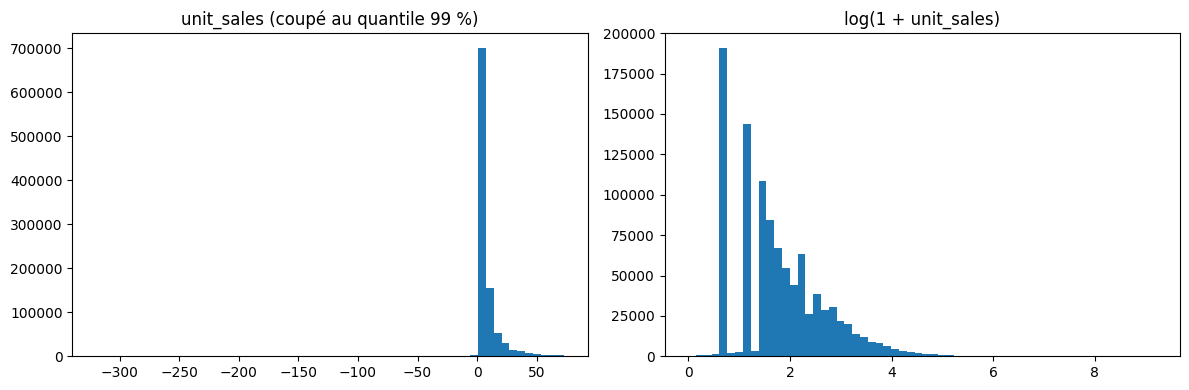

=== 4. Ventes moyennes par jour de la semaine (0 = lundi, 6 = dimanche) ===
date
0     8.37
1     7.83
2     8.16
3     7.11
4     7.93
5     9.99
6    10.75
Name: unit_sales, dtype: float64


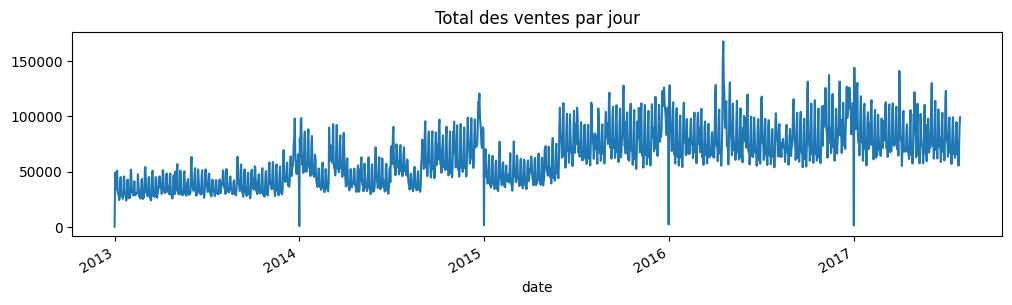


=== 5. Vente moyenne par famille (top 10) ===
item_nbr
BEVERAGES           15.05
LIQUOR,WINE,BEER    14.17
PRODUCE             13.41
PREPARED FOODS      12.72
POULTRY             11.06
DELI                 8.71
FROZEN FOODS         7.88
GROCERY I            7.84
DAIRY                6.75
MEATS                6.50
Name: unit_sales, dtype: float64

=== Vente moyenne avec / sans promotion ===
onpromotion
<NA>    8.63
Name: unit_sales, dtype: float64


In [20]:
# --- 1.9 La cible : unit_sales ------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt

y = train["unit_sales"]

# ÉTAPE 1 : les chiffres de base
print("=== 1. Résumé de unit_sales ===")
print(y.describe().round(2))
print()
print(f"ventes négatives (retours) : {(y < 0).sum():,}  ({(y < 0).mean():.3%})")
print(f"ventes égales à zéro       : {(y == 0).sum():,}  ({(y == 0).mean():.3%})")
print(f"ventes positives           : {(y > 0).sum():,}  ({(y > 0).mean():.3%})")
print()
# Les quantiles : 50 % des lignes ont une vente inférieure à la médiane, etc.
print("quantiles :")
print(y.quantile([0.5, 0.9, 0.99, 0.999, 0.9999]).round(2))

# ÉTAPE 2 : la forme de la distribution (asymétrie)
# skew > 1 = beaucoup de petites valeurs et quelques très grandes (queue à droite)
print()
print("=== 2. Asymétrie (skewness) ===")
print("brute            :", round(y.skew(), 2))
# log1p(x) = log(1 + x). On remplace les retours négatifs par 0 pour pouvoir prendre le log.
y_log = np.log1p(y.clip(lower=0))
print("après log1p      :", round(y_log.skew(), 2), "   (plus proche de 0 = plus symétrique)")

# ÉTAPE 3 : graphiques (sur un échantillon pour aller vite)
echantillon = y.sample(n=min(1_000_000, len(y)), random_state=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogramme brut, coupé au quantile 99 % pour que le graphique reste lisible
coupe = echantillon.quantile(0.99)
axes[0].hist(echantillon[echantillon <= coupe], bins=60)
axes[0].set_title("unit_sales (coupé au quantile 99 %)")

axes[1].hist(np.log1p(echantillon.clip(lower=0)), bins=60)
axes[1].set_title("log(1 + unit_sales)")
plt.tight_layout()
plt.show()

# ÉTAPE 4 : la cible varie-t-elle dans le temps ?
print("=== 4. Ventes moyennes par jour de la semaine (0 = lundi, 6 = dimanche) ===")
print(train.groupby(train["date"].dt.dayofweek)["unit_sales"].mean().round(2))

ventes_par_jour = train.groupby("date")["unit_sales"].sum()
ventes_par_jour.plot(figsize=(12, 3), title="Total des ventes par jour")
plt.show()

# ÉTAPE 5 : la cible selon la famille d'articles et la promotion
print()
print("=== 5. Vente moyenne par famille (top 10) ===")
famille = train["item_nbr"].map(items.set_index("item_nbr")["family"])
print(train.groupby(famille, observed=True)["unit_sales"].mean().sort_values(ascending=False).head(10).round(2))

print()
print("=== Vente moyenne avec / sans promotion ===")
print(train.groupby("onpromotion", dropna=False)["unit_sales"].mean().round(2))

In [44]:
# --- 1.10 Le plancher ---------------------------------------------------------
import numpy as np

# ÉTAPE 1 : découper dans le temps (jamais au hasard)
fin_train   = train["date"].max()
debut_valid = fin_train - pd.Timedelta(days=15)          # 16 derniers jours

passe = train[train["date"] < debut_valid]               # sert à calculer les règles
valid = train[train["date"] >= debut_valid].copy()       # sert à les tester

print(f"passé      : {len(passe):,} lignes, jusqu'au {passe['date'].max().date()}")
print(f"validation : {len(valid):,} lignes, du {debut_valid.date()} au {fin_train.date()}")

# ÉTAPE 2 : une fonction pour mesurer l'erreur
# RMSLE : erreur sur le logarithme des ventes, qui limite le poids des très grosses ventes.
# MAE   : erreur moyenne en unités vendues (facile à comprendre).
# On met les retours (négatifs) à 0 pour ce calcul.
resultats = []

def mesurer(nom, prediction):
    vrai = valid["unit_sales"].clip(lower=0).to_numpy()
    pred = np.clip(np.asarray(prediction, dtype="float64"), 0, None)
    rmsle = np.sqrt(np.mean((np.log1p(pred) - np.log1p(vrai)) ** 2))
    mae = np.mean(np.abs(pred - vrai))
    resultats.append((nom, round(rmsle, 4), round(mae, 3)))

# ÉTAPE 3 : les règles simples, de la plus bête à la plus fine

# Règle 0 : toujours prédire 0 (c'est la soumission de référence du carnet de départ)
mesurer("0 partout", np.zeros(len(valid)))

# Règle 1 : la moyenne de toutes les ventes du passé
moyenne_globale = passe["unit_sales"].clip(lower=0).mean()
mesurer("moyenne globale", np.full(len(valid), moyenne_globale))

# Règle 2 : la moyenne de l'ARTICLE (tous magasins confondus)
moy_article = (passe.assign(v=passe["unit_sales"].clip(lower=0))
               .groupby("item_nbr")["v"].mean().rename("moy_article"))
valid = valid.merge(moy_article, on="item_nbr", how="left")
mesurer("moyenne par article", valid["moy_article"].fillna(moyenne_globale))

# Règle 3 : la moyenne du COUPLE (magasin, article)
moy_couple = (passe.assign(v=passe["unit_sales"].clip(lower=0))
              .groupby(["store_nbr", "item_nbr"])["v"].mean().rename("moy_couple"))
valid = valid.merge(moy_couple, on=["store_nbr", "item_nbr"], how="left")
mesurer("moyenne par (magasin, article)",
        valid["moy_couple"].fillna(valid["moy_article"]).fillna(moyenne_globale))

# Règle 4 : même jour de la semaine, moyenne des 4 dernières semaines
# (on tient compte du rythme hebdomadaire : le samedi ne ressemble pas au mardi)
recent = passe[passe["date"] >= debut_valid - pd.Timedelta(days=28)].copy()
recent["jour"] = recent["date"].dt.dayofweek
recent["v"] = recent["unit_sales"].clip(lower=0)
moy_jour = (recent.groupby(["store_nbr", "item_nbr", "jour"])["v"].mean().rename("moy_jour"))

valid["jour"] = valid["date"].dt.dayofweek
valid = valid.merge(moy_jour, on=["store_nbr", "item_nbr", "jour"], how="left")
mesurer("même jour, 4 dernières semaines",
        valid["moy_jour"].fillna(valid["moy_couple"])
                         .fillna(valid["moy_article"]).fillna(moyenne_globale))

# ÉTAPE 4 : le tableau final
print()
tableau = pd.DataFrame(resultats, columns=["règle", "RMSLE", "MAE"]).sort_values("RMSLE")
print(tableau.to_string(index=False))

print()
print("lignes de validation sans historique sur le couple (magasin, article) :",
      f"{valid['moy_couple'].isna().sum():,}  ({valid['moy_couple'].isna().mean():.2%})")

passé      : 12,083,439 lignes, jusqu'au 2017-07-14
validation : 164,881 lignes, du 2017-07-15 au 2017-07-30

                          règle  RMSLE   MAE
même jour, 4 dernières semaines 0.5899 3.824
 moyenne par (magasin, article) 0.6131 4.251
            moyenne par article 0.8028 5.819
                moyenne globale 1.0411 7.353
                      0 partout 1.8774 7.514

lignes de validation sans historique sur le couple (magasin, article) : 322  (0.20%)


In [23]:
# --- 1.11 La métrique ---------------------------------------------------------
import numpy as np

# ÉTAPE 1 : les prédictions des règles du plancher (calculées en 1.10)
preds = {
    "0 partout":           np.zeros(len(valid)),
    "moyenne globale":     np.full(len(valid), moyenne_globale),
    "moyenne par article": valid["moy_article"].fillna(moyenne_globale).to_numpy(),
    "moyenne par couple":  valid["moy_couple"].fillna(valid["moy_article"])
                                             .fillna(moyenne_globale).to_numpy(),
    "même jour, 4 sem.":   valid["moy_jour"].fillna(valid["moy_couple"])
                                            .fillna(valid["moy_article"])
                                            .fillna(moyenne_globale).to_numpy(),
}

vrai = valid["unit_sales"].clip(lower=0).to_numpy()      # retours mis à 0

# Poids : un article périssable compte 1,25 fois plus (une erreur sur un produit frais coûte plus cher)
perissable = valid["item_nbr"].map(items.set_index("item_nbr")["perishable"]).fillna(0).to_numpy()
poids = 1.0 + 0.25 * perissable

# ÉTAPE 2 : les métriques candidates
def mae(p, y):                 # erreur moyenne, en unités vendues
    return np.mean(np.abs(p - y))

def rmse(p, y):                # comme MAE mais les grosses erreurs pèsent beaucoup plus
    return np.sqrt(np.mean((p - y) ** 2))

def rmsle(p, y):               # erreur sur le logarithme : erreurs relatives, grosses ventes calmées
    return np.sqrt(np.mean((np.log1p(p) - np.log1p(y)) ** 2))

def wrmsle(p, y):              # RMSLE avec le poids périssable
    return np.sqrt(np.sum(poids * (np.log1p(p) - np.log1p(y)) ** 2) / np.sum(poids))

def wape(p, y):                # erreur totale rapportée aux ventes totales (en %)
    return np.sum(np.abs(p - y)) / np.sum(y)

# ÉTAPE 3 : tableau règle x métrique
lignes = []
for nom, p in preds.items():
    p = np.clip(np.asarray(p, dtype="float64"), 0, None)
    lignes.append({"règle": nom, "MAE": mae(p, vrai), "RMSE": rmse(p, vrai),
                   "RMSLE": rmsle(p, vrai), "WRMSLE": wrmsle(p, vrai),
                   "WAPE": wape(p, vrai), "biais": np.mean(p - vrai)})
tableau = pd.DataFrame(lignes).set_index("règle")

print("=== 1. Scores (plus petit = meilleur) ===")
print(tableau.round(3).to_string())

print()
print("=== 2. Classement des règles selon chaque métrique (1 = meilleure) ===")
print(tableau.drop(columns="biais").rank().astype(int).to_string())

# ÉTAPE 4 : pourquoi certaines métriques sont inutilisables ici
print()
print("=== 3. Points de vigilance ===")
print(f"lignes de validation avec une vente de 0 : {(vrai == 0).mean():.2%}"
      "   -> MAPE (erreur en %) impossible : division par 0")
print(f"part des ventes totales portée par le 1 % de lignes les plus grosses : "
      f"{np.sort(vrai)[-len(vrai)//100:].sum() / vrai.sum():.1%}"
      "   -> RMSE dominée par ces lignes")
print(f"part de lignes périssables : {perissable.mean():.2%}")

=== 1. Scores (plus petit = meilleur) ===
                       MAE    RMSE  RMSLE  WRMSLE   WAPE  biais
règle                                                          
0 partout            7.514  16.191  1.877   1.889  1.000 -7.514
moyenne globale      7.353  14.387  1.041   1.036  0.978  1.136
moyenne par article  5.819  12.941  0.803   0.804  0.774  0.858
moyenne par couple   4.251  11.192  0.613   0.612  0.566  0.770
même jour, 4 sem.    3.824  12.573  0.590   0.588  0.509  0.505

=== 2. Classement des règles selon chaque métrique (1 = meilleure) ===
                     MAE  RMSE  RMSLE  WRMSLE  WAPE
règle                                              
0 partout              5     5      5       5     5
moyenne globale        4     4      4       4     4
moyenne par article    3     3      3       3     3
moyenne par couple     2     1      2       2     2
même jour, 4 sem.      1     2      1       1     1

=== 3. Points de vigilance ===
lignes de validation avec une vente de 0 :

In [24]:
# --- 1.12 Le coût des erreurs -------------------------------------------------
import numpy as np

# ÉTAPE 1 : les hypothèses de coût (À JUSTIFIER dans votre rendu)
# Le jeu de données ne donne AUCUN prix : ce sont des hypothèses, à vous de les défendre.
# Unité de référence : 1 unité manquante (vente perdue) coûte 1.
COUT_RUPTURE            = 1.0   # par unité demandée mais pas en rayon (marge perdue)
COUT_INVENDU_PERISSABLE = 1.0   # par unité en trop sur un produit frais (jetée)
COUT_INVENDU_SEC        = 0.2   # par unité en trop sur un produit qui se garde (stock immobilisé)

est_perissable = perissable == 1
cout_trop = np.where(est_perissable, COUT_INVENDU_PERISSABLE, COUT_INVENDU_SEC)

def cout_total(p, y=vrai):
    """Coût total d'une prédiction p face aux ventes réelles y."""
    p = np.clip(np.asarray(p, dtype="float64"), 0, None)
    manque  = np.clip(y - p, 0, None)      # unités qu'on n'avait pas prévues
    en_trop = np.clip(p - y, 0, None)      # unités prévues en trop
    return np.sum(COUT_RUPTURE * manque + cout_trop * en_trop)

# ÉTAPE 2 : le coût de chaque règle du plancher
print("=== 1. Coût de chaque règle ===")
lignes = []
for nom, p in preds.items():
    p = np.clip(np.asarray(p, dtype="float64"), 0, None)
    manque  = np.clip(vrai - p, 0, None)
    en_trop = np.clip(p - vrai, 0, None)
    lignes.append({
        "règle": nom,
        "unités manquantes": manque.sum(),
        "unités en trop": en_trop.sum(),
        "coût total": cout_total(p),
        "coût par ligne": cout_total(p) / len(vrai),
    })
tableau = pd.DataFrame(lignes).set_index("règle").sort_values("coût total")
print(tableau.round(2).to_string())

# ÉTAPE 3 : le classement dépend-il des hypothèses ?
# On fait varier le coût d'un invendu périssable : le meilleur choix change-t-il ?
print()
print("=== 2. Meilleure règle selon le coût d'un invendu périssable ===")
for c in [0.2, 0.5, 1.0, 2.0, 4.0]:
    cout_trop_test = np.where(est_perissable, c, COUT_INVENDU_SEC)
    totaux = {}
    for nom, p in preds.items():
        p = np.clip(np.asarray(p, dtype="float64"), 0, None)
        totaux[nom] = np.sum(COUT_RUPTURE * np.clip(vrai - p, 0, None)
                             + cout_trop_test * np.clip(p - vrai, 0, None))
    print(f"invendu périssable = {c:>3} x rupture  ->  meilleure règle : {min(totaux, key=totaux.get)}")

# ÉTAPE 4 : faut-il prédire un peu plus haut ou un peu plus bas ?
# On multiplie la meilleure règle par un facteur k et on cherche le k de coût minimal.
# Périssables et produits secs ont des coûts différents, donc des k différents.
print()
print("=== 3. Facteur correcteur optimal (sur la meilleure règle) ===")
meilleure = tableau.index[0]
base = np.clip(np.asarray(preds[meilleure], dtype="float64"), 0, None)
facteurs = np.arange(0.5, 1.81, 0.1)

for nom_groupe, masque in (("périssables", est_perissable), ("non périssables", ~est_perissable)):
    couts = []
    for k in facteurs:
        p = base[masque] * k
        y = vrai[masque]
        c_trop = cout_trop[masque]
        couts.append(np.sum(COUT_RUPTURE * np.clip(y - p, 0, None) + c_trop * np.clip(p - y, 0, None)))
    k_opt = facteurs[int(np.argmin(couts))]
    gain = 1 - min(couts) / couts[int(np.argmin(np.abs(facteurs - 1.0)))]
    print(f"{nom_groupe:16s} : facteur optimal = {k_opt:.1f}   (gain de coût vs facteur 1,0 : {gain:.1%})")

# ÉTAPE 5 : le contexte pour votre rendu
print()
print("=== 4. Repères ===")
print(f"meilleure règle selon le coût : {meilleure}")
print(f"part de lignes périssables    : {est_perissable.mean():.2%}")
print(f"part des ventes réelles sur périssables : {vrai[est_perissable].sum() / vrai.sum():.2%}")

=== 1. Coût de chaque règle ===
                     unités manquantes  unités en trop  coût total  coût par ligne
règle                                                                             
même jour, 4 sem.            273689.55       356887.12   414531.18            2.51
moyenne par couple           286923.66       413930.99   448298.65            2.72
moyenne par article          408928.91       550467.65   637950.23            3.87
moyenne globale              512474.21       699821.33   765850.65            4.64
0 partout                   1238943.53            0.00  1238943.53            7.51

=== 2. Meilleure règle selon le coût d'un invendu périssable ===
invendu périssable = 0.2 x rupture  ->  meilleure règle : même jour, 4 sem.
invendu périssable = 0.5 x rupture  ->  meilleure règle : même jour, 4 sem.
invendu périssable = 1.0 x rupture  ->  meilleure règle : même jour, 4 sem.
invendu périssable = 2.0 x rupture  ->  meilleure règle : même jour, 4 sem.
invendu périssabl

# Favorita — Sujet 02

**Séance :** 02 
**Nom :** ALIA Holmi

**Porteur :** P3  

**Étapes assignées :**  
2.3 : Le plancher de controle

2.6 : Les comparaisons


In [45]:
# --- Tout-en-un : préparation + 1.10 (à exécuter avant 2.3) --------------------
import os
from pathlib import Path
import numpy as np
import pandas as pd

# 1) Trouver le dossier des données
FICHIERS_ATTENDUS = ['train.csv', 'horizon.csv', 'items.csv', 'stores.csv',
                     'holidays_events.csv', 'oil.csv', 'transactions.csv']
DOSSIER = None
for racine, dossiers, fichiers in os.walk("/kaggle/input"):
    if all(f in fichiers for f in FICHIERS_ATTENDUS):
        DOSSIER = Path(racine)
if DOSSIER is None:
    raise FileNotFoundError("Les 7 fichiers sont introuvables : vérifiez que le dataset est dans Input.")
print("dossier de données :", DOSSIER)

# 2) Charger
train   = pd.read_csv(DOSSIER / "train.csv",   parse_dates=["date"])
horizon = pd.read_csv(DOSSIER / "horizon.csv", parse_dates=["date"])
items   = pd.read_csv(DOSSIER / "items.csv")
print(f"train : {len(train):,} lignes | horizon : {len(horizon):,} lignes")

# 3) Typer
train["onpromotion"]   = train["onpromotion"].astype("boolean")
horizon["onpromotion"] = horizon["onpromotion"].astype("boolean")
for t in (train, horizon):
    t["store_nbr"] = t["store_nbr"].astype("int16")
    t["item_nbr"]  = t["item_nbr"].astype("int32")
items["family"] = items["family"].astype("category")

# 4) 1.10 : le plancher (découpage dans le temps)
fin_train   = train["date"].max()
debut_valid = fin_train - pd.Timedelta(days=15)          # 16 derniers jours

passe = train[train["date"] < debut_valid]               # sert à calculer les règles
valid = train[train["date"] >= debut_valid].copy()       # sert à les tester
print(f"passé      : {len(passe):,} lignes, jusqu'au {passe['date'].max().date()}")
print(f"validation : {len(valid):,} lignes, du {debut_valid.date()} au {fin_train.date()}")

resultats = []
def mesurer(nom, prediction):
    vrai_ = valid["unit_sales"].clip(lower=0).to_numpy()
    pred = np.clip(np.asarray(prediction, dtype="float64"), 0, None)
    rmsle_ = np.sqrt(np.mean((np.log1p(pred) - np.log1p(vrai_)) ** 2))
    mae_ = np.mean(np.abs(pred - vrai_))
    resultats.append((nom, round(rmsle_, 4), round(mae_, 3)))

mesurer("0 partout", np.zeros(len(valid)))

moyenne_globale = passe["unit_sales"].clip(lower=0).mean()
mesurer("moyenne globale", np.full(len(valid), moyenne_globale))

moy_article = (passe.assign(v=passe["unit_sales"].clip(lower=0))
               .groupby("item_nbr")["v"].mean().rename("moy_article"))
valid = valid.merge(moy_article, on="item_nbr", how="left")
mesurer("moyenne par article", valid["moy_article"].fillna(moyenne_globale))

moy_couple = (passe.assign(v=passe["unit_sales"].clip(lower=0))
              .groupby(["store_nbr", "item_nbr"])["v"].mean().rename("moy_couple"))
valid = valid.merge(moy_couple, on=["store_nbr", "item_nbr"], how="left")
mesurer("moyenne par (magasin, article)",
        valid["moy_couple"].fillna(valid["moy_article"]).fillna(moyenne_globale))

recent = passe[passe["date"] >= debut_valid - pd.Timedelta(days=28)].copy()
recent["jour"] = recent["date"].dt.dayofweek
recent["v"] = recent["unit_sales"].clip(lower=0)
moy_jour = recent.groupby(["store_nbr", "item_nbr", "jour"])["v"].mean().rename("moy_jour")

valid["jour"] = valid["date"].dt.dayofweek
valid = valid.merge(moy_jour, on=["store_nbr", "item_nbr", "jour"], how="left")
mesurer("même jour, 4 dernières semaines",
        valid["moy_jour"].fillna(valid["moy_couple"])
                         .fillna(valid["moy_article"]).fillna(moyenne_globale))

print()
tableau = pd.DataFrame(resultats, columns=["règle", "RMSLE", "MAE"]).sort_values("RMSLE")
print(tableau.to_string(index=False))

# 5) Contrôle final
print()
for nom in ["DOSSIER", "train", "items", "passe", "valid", "moyenne_globale"]:
    print(nom, "->", "défini" if nom in globals() else "MANQUANT")

dossier de données : /kaggle/input/datasets/holmialia/favorita-data
train : 12,248,320 lignes | horizon : 277,568 lignes
passé      : 12,083,439 lignes, jusqu'au 2017-07-14
validation : 164,881 lignes, du 2017-07-15 au 2017-07-30

                          règle  RMSLE   MAE
même jour, 4 dernières semaines 0.5899 3.824
 moyenne par (magasin, article) 0.6131 4.251
            moyenne par article 0.8028 5.819
                moyenne globale 1.0411 7.353
                      0 partout 1.8774 7.514

DOSSIER -> défini
train -> défini
items -> défini
passe -> défini
valid -> défini
moyenne_globale -> défini


In [33]:
for nom in ["preds", "score", "METRIQUES", "METRIQUE_CHOISIE", "plancher_nom", "plancher_pred", "vrai", "poids", "perissable"]:
    print(nom, "->", "défini" if nom in globals() else "MANQUANT")

preds -> défini
score -> MANQUANT
METRIQUES -> MANQUANT
METRIQUE_CHOISIE -> MANQUANT
plancher_nom -> MANQUANT
plancher_pred -> MANQUANT
vrai -> défini
poids -> défini
perissable -> défini


In [51]:

print("Dimensions de train :", train.shape)
print("Dimensions de valid :", valid.shape)
print("Mémoire utilisée par train (Mo) :",
      round(train.memory_usage(deep=True).sum() / 1024**2, 2))


Dimensions de train : (12248320, 6)
Dimensions de valid : (164881, 10)
Mémoire utilisée par train (Mo) : 373.79


In [53]:

# ==========================================
# ÉTAPE 1 : EXPLORATION DES DONNÉES
# ==========================================

import pandas as pd
import numpy as np

# 1. Dimensions des données
print("===== DIMENSIONS =====")
print("Train :", train.shape)
print("Valid :", valid.shape)

# 2. Liste des colonnes
print("\n===== COLONNES DE TRAIN =====")
print(train.columns.tolist())

print("\n===== COLONNES DE VALID =====")
print(valid.columns.tolist())

# 3. Types de données
print("\n===== TYPES DE TRAIN =====")
print(train.dtypes)

print("\n===== TYPES DE VALID =====")
print(valid.dtypes)

# 4. Aperçu des données
print("\n===== APERÇU DE TRAIN =====")
display(train.head())

print("\n===== APERÇU DE VALID =====")
display(valid.head())

# 5. Valeurs manquantes
print("\n===== VALEURS MANQUANTES : TRAIN =====")
display(train.isnull().sum().to_frame("Valeurs manquantes"))

print("\n===== VALEURS MANQUANTES : VALID =====")
display(valid.isnull().sum().to_frame("Valeurs manquantes"))

# 6. Mémoire utilisée
print("\n===== MÉMOIRE =====")
memoire_train = train.memory_usage(deep=True).sum() / (1024**2)
memoire_valid = valid.memory_usage(deep=True).sum() / (1024**2)

print(f"Mémoire de train : {memoire_train:.2f} Mo")
print(f"Mémoire de valid : {memoire_valid:.2f} Mo")

# 7. Vérifier les colonnes communes
print("\n===== COMPARAISON DES COLONNES =====")
colonnes_communes = train.columns.intersection(valid.columns)

print("Colonnes communes :", colonnes_communes.tolist())
print("Colonnes uniquement dans train :",
      train.columns.difference(valid.columns).tolist())
print("Colonnes uniquement dans valid :",
      valid.columns.difference(train.columns).tolist())


===== DIMENSIONS =====
Train : (12248320, 6)
Valid : (164881, 10)

===== COLONNES DE TRAIN =====
['id', 'date', 'store_nbr', 'item_nbr', 'unit_sales', 'onpromotion']

===== COLONNES DE VALID =====
['id', 'date', 'store_nbr', 'item_nbr', 'unit_sales', 'onpromotion', 'moy_article', 'moy_couple', 'jour', 'moy_jour']

===== TYPES DE TRAIN =====
id                      int64
date           datetime64[ns]
store_nbr               int16
item_nbr                int32
unit_sales            float64
onpromotion           boolean
dtype: object

===== TYPES DE VALID =====
id                      int64
date           datetime64[ns]
store_nbr               int16
item_nbr                int32
unit_sales            float64
onpromotion           boolean
moy_article           float64
moy_couple            float64
jour                    int32
moy_jour              float64
dtype: object

===== APERÇU DE TRAIN =====


,id,date,store_nbr,item_nbr,unit_sales,onpromotion
0,9,2013-01-01,25,114790,3.0,<NA>
1,10,2013-01-01,25,114800,1.0,<NA>
2,14,2013-01-01,25,115720,5.0,<NA>
3,15,2013-01-01,25,115850,1.0,<NA>
4,30,2013-01-01,25,158680,1.0,<NA>



===== APERÇU DE VALID =====


,id,date,store_nbr,item_nbr,unit_sales,onpromotion,moy_article,moy_couple,jour,moy_jour
0,122137475,2017-07-15,1,103520,1.0,<NA>,3.797539,2.924339,5,1.250000
1,122137488,2017-07-15,1,112830,5.0,<NA>,4.679984,2.947415,5,2.250000
2,122137490,2017-07-15,1,114790,5.0,<NA>,12.457427,4.861023,5,4.000000
3,122137492,2017-07-15,1,114800,3.0,<NA>,12.117982,4.890780,5,4.500000
4,122137495,2017-07-15,1,115720,2.0,<NA>,6.743713,3.346209,5,1.666667



===== VALEURS MANQUANTES : TRAIN =====


,Valeurs manquantes
id,0
date,0
store_nbr,0
item_nbr,0
unit_sales,0
onpromotion,12248320



===== VALEURS MANQUANTES : VALID =====


,Valeurs manquantes
id,0
date,0
store_nbr,0
item_nbr,0
unit_sales,0
onpromotion,164881
moy_article,0
moy_couple,322
jour,0
moy_jour,5259



===== MÉMOIRE =====
Mémoire de train : 373.79 Mo
Mémoire de valid : 9.43 Mo

===== COMPARAISON DES COLONNES =====
Colonnes communes : ['id', 'date', 'store_nbr', 'item_nbr', 'unit_sales', 'onpromotion']
Colonnes uniquement dans train : []
Colonnes uniquement dans valid : ['jour', 'moy_article', 'moy_couple', 'moy_jour']
